<a href="https://colab.research.google.com/github/samueldarmaw/Computer-Vision-Project/blob/sam/ComputerVisionProject.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<center><h1> <b> Object Detection Using YOLO <b> </h1></center>

This tutorial is designed to provide a comprehensive understanding of how to use YOLO, a state-of-the-art method in computer vision, for detecting objects in images.

Object detection and classification is a key technology in many areas, such as automated vehicles, security, and even healthcare.

We will begin with the basics of preparing (pre processing) an image dataset, ensuring it is ready for effective model training.We will then explore how YOLO, a type of convolutional neural network, automatically extracts features from images to recognize different objects. Understanding this process is crucial for grasping how YOLO operates.

The core of this tutorial is focused on transfer learning using YOLO. We will teach you how to take a pre-trained YOLO model and adapt it to a new dataset. This technique is efficient and powerful, allowing us to harness the strengths of YOLO with less computational effort.

By the end of this tutorial, you will have hands-on experience with preparing data, implementing YOLO, and understanding the principles behind it. This tutorial aims to equip students with practical skills and knowledge in one of the most exciting fields in technology.

Since its inception, the YOLO family of object detection models has come a long way. YOLOv8 is the most recent addition to this famous anchor-based single-shot family of object detectors. It comes with a bunch of improvements which include state-of-the-art accuracy and speed.  In this article, we will be fine tuning the YOLOv8 object detection model on a real-world pothole detection dataset.

In the previous lecture, you were asked to make your own custom datasets for a project you want to work on. Today we will explore how to finetune YOLO on a certain dataset.  

Importing required Libraries

In [7]:
from google.colab import drive
drive.mount('/content/drive')

ModuleNotFoundError: No module named 'google'

In [ ]:
import numpy as np # linear algebra
#import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
#import matplotlib.pyplot as plt
#import tensorflow as tf
#from tensorflow import keras
#import cv2
#import seaborn as sns
import glob
import xml.etree.ElementTree as ET
from PIL import Image
import os
os.environ["TORCH_BLAS_PREFER_HIPBLASLT"] = "0"
#os.environ["PYTORCH_HIP_ALLOC_CONF"] = "expandable_segments:True"
import shutil

import torch
print(torch.cuda.is_available(), torch.cuda.get_device_name(0)) #running with local GPU
torch.cuda.set_per_process_memory_fraction(0.9) #limit GPU vram to 90%

True AMD Radeon RX 9070 XT


# Dataset Description






Fruit Images for Object Detection

available on kaggle => https://www.kaggle.com/datasets/mbkinaci/fruit-images-for-object-detection


- 240 images in train folder. 60 images in test folder.

- 3 different fruits:

    - Apple

    - Banana

    - Orange

The labels are in xml format, which is Extensible markup language.Storing image dataset labels in XML format is quite common. XML provides a clear, hierarchical structure which is ideal for representing the complex data associated with image labels. This includes not just the class of the object, but potentially a wealth of other information like bounding box coordinates, object IDs, and additional metadata.


# Data Preprocessing

For preprocessing:
- We have to convert the dataset into that acceptable by YOLO.
  - Heirarchy of folders should be the one accepted by YOLO
  - Labels format should be darknet YOLO.
  - Labels files should be .txt files
- Check and see if there are any missing labels or images. And remove them from dataset.


## Heirarchy of Folders correction

Defining paths to train, test, and validation folders.

In [ ]:
# Use the local project dataset folders since its included in the repo
project_dir = os.path.abspath('/content/drive/MyDrive/Posture Check Computer Vision IAT360/sitting-posture')
train_dir = os.path.join(project_dir, 'train')
valid_dir = os.path.join(project_dir, 'valid')
test_dir = os.path.join(project_dir, 'test')

train_images = os.path.join(train_dir, 'images')
train_labels = os.path.join(train_dir, 'labels')
valid_images = os.path.join(valid_dir, 'images')
valid_labels = os.path.join(valid_dir, 'labels')
test_images = os.path.join(test_dir, 'images')
test_labels = os.path.join(test_dir, 'labels')

print(train_dir)
print(valid_dir)
print(test_dir)

/content/drive/MyDrive/Posture Check Computer Vision IAT360/sitting-posture/train
/content/drive/MyDrive/Posture Check Computer Vision IAT360/sitting-posture/valid
/content/drive/MyDrive/Posture Check Computer Vision IAT360/sitting-posture/test


**NOT NEEDED AS ROBOFLOW EXPORTS THE FILE USING YOLO26 FORMAT**

The train and test folders have all the images and labels together.

But for YOLO, the directories should be in:

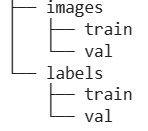


Making directories according to above struture of folders

In [ ]:
#import os
#run it once for making directories

#os.makedirs('/content/drive/MyDrive/Tutorials/Datasets/FRUIT DATA/Final_data')
#os.makedirs('/content/drive/MyDrive/Tutorials/Datasets/FRUIT DATA/Final_data/images')
#os.makedirs('/content/drive/MyDrive/Tutorials/Datasets/FRUIT DATA/Final_data/labels')
#os.makedirs('/content/drive/MyDrive/Tutorials/Datasets/FRUIT DATA/Final_data/images/train')
#os.makedirs('/content/drive/MyDrive/Tutorials/Datasets/FRUIT DATA/Final_data/images/val')
#os.makedirs('/content/drive/MyDrive/Tutorials/Datasets/FRUIT DATA/Final_data/labels/train')
#os.makedirs('/content/drive/MyDrive/Tutorials/Datasets/FRUIT DATA/Final_data/labels/val')

In [ ]:
#set the paths to labels and images directory ALREADY DONE IN CELL 6
#label_dir= "/content/drive/MyDrive/Tutorials/Datasets/FRUIT DATA/Final_data/labels"
#image_dir="/content/drive/MyDrive/Tutorials/Datasets/FRUIT DATA/Final_data/images"

Copy XML files and jpg files from the train folder to the folders created.

In [ ]:
#import shutil
#run it once for copying!
#for file in os.listdir(train_dir):
#    if file.endswith(".xml"):
#        shutil.copy(os.path.join(train_dir, file), os.path.join(label_dir, "train"))
#    if file.endswith(".jpg"):
#        image = Image.open(os.path.join(train_dir, file))
#       image = image.convert("RGB")
#        new_filename = os.path.splitext(file)[0] + ".jpg"
#        image.save(os.path.join(image_dir,"train", new_filename), "JPEG")
#        #shutil.copy(os.path.join(train_dir, file), os.path.join(image_dir, "train"))


#Copy XML files and jpg files from the test folder to the folders created.
#for file in os.listdir(test_dir):
#    if file.endswith(".xml"):
#        shutil.copy(os.path.join(test_dir, file), os.path.join(label_dir, "val"))
#    if file.endswith(".jpg"):
#        image = Image.open(os.path.join(test_dir, file))
#        image = image.convert("RGB")
#        new_filename = os.path.splitext(file)[0] + ".jpg"
#        image.save(os.path.join(image_dir,"val", new_filename), "JPEG")
        #shutil.copy(os.path.join(test_dir, file), os.path.join(image_dir, "val"))


/usr/local/lib/python3.12/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Visualizing somme pictures from the dataset

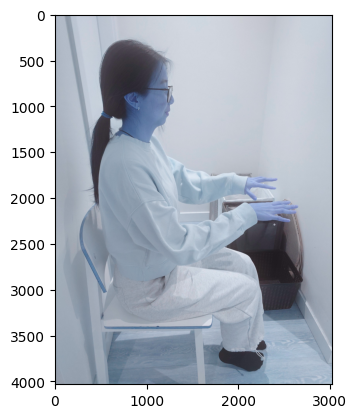

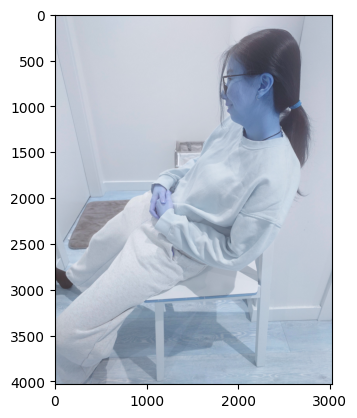

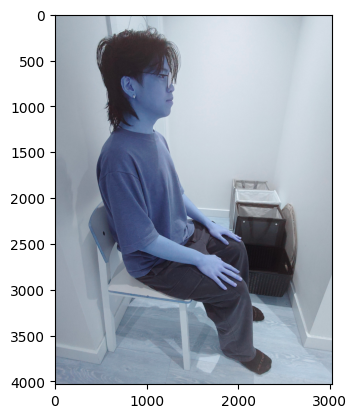

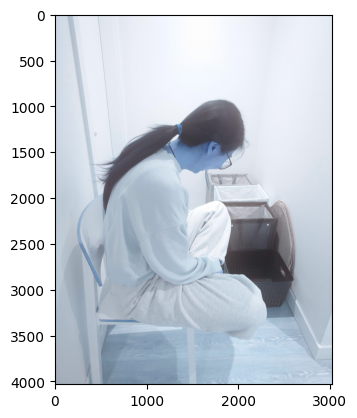

In [ ]:
#visualize first four sample images from train data
for idx, image in enumerate(os.listdir(os.path.join(train_images))):
    img = cv2.imread(os.path.join(train_images, image))
    plt.imshow(img)
    plt.show()

    if idx == 3:
        break

## Creating Text files for labels
**TEXT FILES ALREADY MADE WHILE EXPORTING FROM ROBOLOW**

Creating Dataframes from .xml files, from which we will eventually create .txt file for each image


In [ ]:
# @title Bounding Box Train Data Base (NOT POLYGONS DO NOT USE)
#read bounding box train data (NOT POLYGONS DO NOT USE) XXXXXXX
#import glob
#import xml.etree.ElementTree as ET

df = {'name': [],
      'label': [],
      'width': [],
      'height': [],
     'xmin': [],
     'ymin': [],
     'xmax': [],
     'ymax': []}


#This is the way to handle xml format files which are in heirarchial form (trees).

for idx, anno in enumerate(glob.glob(label_dir+"/train" + '/*.xml')):

    trees = ET.parse(anno)

    print(anno)
    root = trees.getroot()
    width, height = [], []
    for item in root.iter():
        print(item)

        if item.tag == 'size':
            for attr in list(item):
                if attr.tag == 'width':
                    width =int(round(float(attr.text)))
                if attr.tag == 'height':
                    height = int(round(float(attr.text)))

        if item.tag == 'object':
            for attr in list(item):
                if 'name' in attr.tag:
                    label = attr.text
                    df['label'] += [label]
                    df['width'] += [width]
                    df['height'] += [height]
                    df['name'] += [anno.split('/')[-1][0:-4]]

                if 'bndbox' in attr.tag:
                    for dim in attr:
                        if dim.tag == 'xmin':
                            xmin = int(round(float(dim.text)))
                            df['xmin'] += [xmin]

                        if dim.tag == 'ymin':
                            ymin = int(round(float(dim.text)))
                            df['ymin'] += [ymin]
                        if dim.tag == 'xmax':
                            xmax = int(round(float(dim.text)))
                            df['xmax'] += [xmax]
                        if dim.tag == 'ymax':
                            ymax = int(round(float(dim.text)))
                            df['ymax'] += [ymax]

In [ ]:
# @title Bounding Box Valid Data Base (NOT POLYGONS DO NOT USE)
#read bounding box valid data (NOT POLYGONS DO NOT USE) XXXXXXXX
#import glob
#import xml.etree.ElementTree as ET

df2 = {'name': [],
      'label': [],
      'width': [],
      'height': [],
     'xmin': [],
     'ymin': [],
     'xmax': [],
     'ymax': []}


#This is the way to handle xml format files which are in heirarchial form (tees).

for idx, anno in enumerate(glob.glob(label_dir+"/val" + '/*.xml')):

    trees = ET.parse(anno)

    #print(anno)
    root = trees.getroot()
    width, height = [], []
    for item in root.iter():
        #print(item)

        if item.tag == 'size':
            for attr in list(item):
                if attr.tag == 'width':
                    width =int(round(float(attr.text)))
                if attr.tag == 'height':
                    height = int(round(float(attr.text)))

        if item.tag == 'object':
            for attr in list(item):
                if 'name' in attr.tag:
                    label = attr.text
                    df2['label'] += [label]
                    df2['width'] += [width]
                    df2['height'] += [height]
                    #dataset['name']+=[anno.split('/')[-1][0:-4]]
                    df2['name'] += [anno.split('/')[-1][0:-4]]

                if 'bndbox' in attr.tag:
                    for dim in attr:
                        if dim.tag == 'xmin':
                            xmin = int(round(float(dim.text)))
                            df2['xmin'] += [xmin]

                        if dim.tag == 'ymin':
                            ymin = int(round(float(dim.text)))
                            df2['ymin'] += [ymin]
                        if dim.tag == 'xmax':
                            xmax = int(round(float(dim.text)))
                            df2['xmax'] += [xmax]
                        if dim.tag == 'ymax':
                            ymax = int(round(float(dim.text)))
                            df2['ymax'] += [ymax]

In [ ]:
#Read YOLO training labels into df (POLYGONS USE THIS)

import glob

df = {'name': [],
      'label': [],
      'class': [],
      'x_center': [],
      'y_center': [],
      'box_width': [],
      'box_height': []}

# Class mapping from sitting-posture/data.yaml
class_map = {0: 'BadPosture', 1: 'GoodPosture'}

for anno in glob.glob(os.path.join(train_labels, '*.txt')):
    file_name = os.path.splitext(os.path.basename(anno))[0]
    with open(anno, 'r') as f:
        for line in f:
            parts = line.strip().split()
            if not parts:
                continue
            class_id = int(parts[0])
            coords = [float(x) for x in parts[1:]]

            # Handles polygon segmentation as well as standard bounding boxes
            if len(coords) == 4:
                xc, yc, w, h = coords
            elif len(coords) >= 6:  # polygon coords (x1, y1, x2, y2, ...)
                xs = coords[0::2]
                ys = coords[1::2]
                xmin, xmax = min(xs), max(xs)
                ymin, ymax = min(ys), max(ys)
                xc = (xmin + xmax) / 2.0
                yc = (ymin + ymax) / 2.0
                w = xmax - xmin
                h = ymax - ymin
            else:
                continue

            df['name'].append(file_name)
            df['class'].append(class_id)
            df['label'].append(class_map.get(class_id, str(class_id)))
            df['x_center'].append(xc)
            df['y_center'].append(yc)
            df['box_width'].append(w)
            df['box_height'].append(h)

print(f"Loaded {len(df['name'])} annotations from {len(set(df['name']))} training images.")

Loaded 886 annotations from 767 training images.


Doing the same for validation data labels.


In [ ]:
#Read YOLO VALID labels into df (POLYGONS USE THIS)

import glob

df2 = {'name': [],
      'label': [],
      'class': [],
      'x_center': [],
      'y_center': [],
      'box_width': [],
      'box_height': []}

for anno in glob.glob(os.path.join(valid_labels, '*.txt')):
    file_name = os.path.splitext(os.path.basename(anno))[0]
    with open(anno, 'r') as f:
        for line in f:
            parts = line.strip().split()
            if not parts:
                continue
            class_id = int(parts[0])
            coords = [float(x) for x in parts[1:]]

            # Handles polygon segmentation as well as standard bounding boxes
            if len(coords) == 4:
                xc, yc, w, h = coords
            elif len(coords) >= 6:  # polygon coords (x1, y1, x2, y2, ...)
                xs = coords[0::2]
                ys = coords[1::2]
                xmin, xmax = min(xs), max(xs)
                ymin, ymax = min(ys), max(ys)
                xc = (xmin + xmax) / 2.0
                yc = (ymin + ymax) / 2.0
                w = xmax - xmin
                h = ymax - ymin
            else:
                continue

            df2['name'].append(file_name)
            df2['class'].append(class_id)
            df2['label'].append(class_map.get(class_id, str(class_id)))
            df2['x_center'].append(xc)
            df2['y_center'].append(yc)
            df2['box_width'].append(w)
            df2['box_height'].append(h)

print(f"Loaded {len(df['name'])} annotations from {len(set(df['name']))} valid images.")

Loaded 886 annotations from 767 valid images.


In [ ]:
import pandas as pd
train_df = pd.DataFrame(df)
val_df=pd.DataFrame(df2)
#df1.head()
val_df.head()

,name,label,class,x_center,y_center,box_width,box_height
0,image_102_jpg.rf.db54eadb76bbf78b60baf3fa0c3f55bc,BadPosture,0,0.665972,0.506641,0.512500,0.327344
1,20261106_181124_JPG.rf.ec8d7bd0ea9def49bd2197f...,BadPosture,0,0.445773,0.572368,0.539075,0.855263
2,20261106_181102_JPG.rf.70752c0bdb2c52201696eef...,GoodPosture,1,0.519936,0.488038,0.633174,0.844498
3,20261106_181108_JPG.rf.5ce09818cde338a98ab096a...,GoodPosture,1,0.365231,0.501794,0.508772,0.996411
4,20261106_181131_JPG.rf.00de3c8eaa6f51526fad5fb...,BadPosture,0,0.500797,0.560407,0.661882,0.690191


In [ ]:
train_df.head(5)

,name,label,class,x_center,y_center,box_width,box_height
0,20261106_174428_JPG.rf.572f83afbd6ea8926417562...,BadPosture,0,0.417065,0.549043,0.717703,0.901914
1,20261106_181117_JPG.rf.63b1c516097c118f5355b7e...,BadPosture,0,0.507177,0.613038,0.693780,0.773923
2,20261106_174344_JPG.rf.89686f1080af4a630d6b55d...,BadPosture,0,0.446571,0.556220,0.633174,0.653110
3,20261106_173928_JPG.rf.46050496177154c8c83b864...,GoodPosture,1,0.470494,0.516148,0.636364,0.967703
4,20261106_174404_JPG.rf.e1c790fe22317d4e576cc7d...,GoodPosture,1,0.446571,0.528708,0.521531,0.942584


Visualizing one of the image in train set with the bounding box

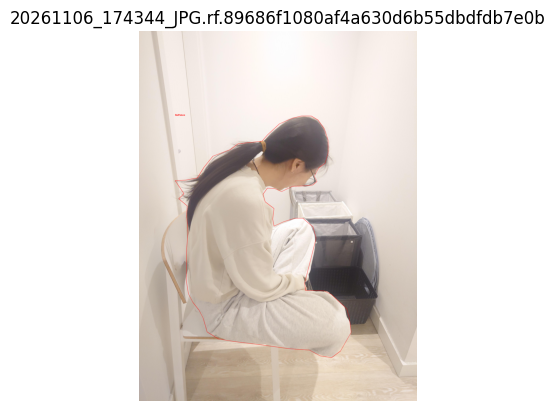

In [ ]:
index = 15  #picture to visualize

#Pick the image name from the labels loaded in Cell 1
names = sorted(set(df['name']))
name = names[index]

# Find the image file (any common extension)
img_path = None
for ext in ['.jpg', '.jpeg', '.png', '.JPG', '.PNG']:
    candidate = os.path.join(train_images, name + ext)
    if os.path.exists(candidate):
        img_path = candidate
        break

image = cv2.imread(img_path, 1)
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)  #OpenCV is BGR, matplotlib expects RGB
h_img, w_img = image.shape[:2]

colors = {0: (255, 0, 0), 1: (0, 200, 0)}  #BadPosture = red, GoodPosture = green

#Read the label file directly
with open(os.path.join(train_labels, name + '.txt')) as f:
    for line in f:
        parts = line.strip().split()
        if not parts:
            continue
        class_id = int(parts[0])
        coords = [float(x) for x in parts[1:]]
        color = colors.get(class_id, (0, 0, 255))
        label = class_map.get(class_id, str(class_id))

        if len(coords) >= 6 and len(coords) % 2 == 0:
            #Polygon: scale normalized points to pixels and draw the outline
            pts = np.array([[x * w_img, y * h_img] for x, y in zip(coords[0::2], coords[1::2])], dtype=np.int32)
            cv2.polylines(image, [pts], isClosed=True, color=color, thickness=2)
            tx, ty = int(pts[:, 0].min()), int(pts[:, 1].min())
        elif len(coords) == 4:
            #Standard box: convert center/size to corners
            xc, yc, w, h = coords
            x1, y1 = int((xc - w / 2) * w_img), int((yc - h / 2) * h_img)
            x2, y2 = int((xc + w / 2) * w_img), int((yc + h / 2) * h_img)
            cv2.rectangle(image, (x1, y1), (x2, y2), color, 2)
            tx, ty = x1, y1
        else:
            continue

        cv2.putText(image, label, (tx, max(ty - 5, 15)), cv2.FONT_HERSHEY_SIMPLEX, 0.6, color, 2)

plt.imshow(image)
plt.title(name)
plt.axis('off')
plt.show()

Checking to see if the above image has bounding boxes around other posture or not.

In [ ]:
train_df["name"][index]
filtered_df = train_df[train_df['name'] == train_df["name"][index]]
print(filtered_df)

                                                 name       label  class  \
15  20261106_181356_JPG.rf.9a8e2e4301e98ba69d8dff8...  BadPosture      0   

    x_center  y_center  box_width  box_height  
15  0.468102  0.558014   0.717703    0.881579  


Checking to see the datatypes of all the columns and if there is any null value that needs to be eliminated from the data.

In [ ]:
val_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 152 entries, 0 to 151
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   name        152 non-null    object 
 1   label       152 non-null    object 
 2   class       152 non-null    int64  
 3   x_center    152 non-null    float64
 4   y_center    152 non-null    float64
 5   box_width   152 non-null    float64
 6   box_height  152 non-null    float64
dtypes: float64(4), int64(1), object(2)
memory usage: 8.4+ KB


What different types of labels are assigned to each sample and checking if they match the provided label/class information, i.e. there are no extra labels due to mistakes in spellings etc.

In [ ]:
print(train_df['label'].unique())
print(val_df['label'].unique())

['BadPosture' 'GoodPosture']
['BadPosture' 'GoodPosture']


We need to map labels to class_ids required for YOLO (DONE EARLIER)

In [ ]:
train_df.head()

,name,label,class,x_center,y_center,box_width,box_height
0,20261106_174428_JPG.rf.572f83afbd6ea8926417562...,BadPosture,0,0.417065,0.549043,0.717703,0.901914
1,20261106_181117_JPG.rf.63b1c516097c118f5355b7e...,BadPosture,0,0.507177,0.613038,0.693780,0.773923
2,20261106_174344_JPG.rf.89686f1080af4a630d6b55d...,BadPosture,0,0.446571,0.556220,0.633174,0.653110
3,20261106_173928_JPG.rf.46050496177154c8c83b864...,GoodPosture,1,0.470494,0.516148,0.636364,0.967703
4,20261106_174404_JPG.rf.e1c790fe22317d4e576cc7d...,GoodPosture,1,0.446571,0.528708,0.521531,0.942584


In [ ]:
# @title Converting the bounding box format to the one required by YOLO: (ALREADY DONE BY ROBOFLOW DON'T RUN)

# (DON'T RUN)
# Training data
train_df['x_center'] = (train_df['xmin']+train_df['xmax'])/(2*train_df["width"])
train_df['y_center'] = (train_df['ymin']+train_df['ymax'])/(2*train_df["height"])
train_df['box_width'] = (train_df['xmax']-train_df['xmin'])/ train_df["width"]
train_df['box_height'] = (train_df['ymax']-train_df['ymin'])/train_df["height"]

#Validation data
val_df['x_center'] = (val_df['xmin']+val_df['xmax'])/(2*val_df["width"])
val_df['y_center'] = (val_df['ymin']+val_df['ymax'])/(2*val_df["height"])
val_df['box_width'] = (val_df['xmax']-val_df['xmin'])/ val_df["width"]
val_df['box_height'] = (val_df['ymax']-val_df['ymin'])/val_df["height"]

Deleting all the sample with Nan values in training and validation data

In [ ]:
#training
print("before deleting (train data): " , train_df.shape)
train_df.replace([np.inf, -np.inf], np.nan, inplace=True)
train_df.dropna(inplace=True)
print("after deleting(train_data): " ,train_df.shape)

#validation
print("before deleting (val data): " , val_df.shape)
val_df.replace([np.inf, -np.inf], np.nan, inplace=True)
val_df.dropna(inplace=True)
print("after deleting(val data): " , val_df.shape)



before deleting (train data):  (886, 7)
after deleting(train_data):  (886, 7)
before deleting (val data):  (152, 7)
after deleting(val data):  (152, 7)


converting the dataframe to type *str* (string) to be stored in text files. (ALREADY EXPORTED AS STRING FROM ROBOFLOW)

In [ ]:
train_df = train_df.astype(str)
val_df = val_df.astype(str)

## Checking Missing Files

Checking the folders if every image file has a corresponding label file


(We will copy the code, we already used in previous turorial after updating)

In [ ]:
#The lists of all the images and labels for train and validation set:
train_images=glob.glob(os.path.join(image_dir, "train",'*.jpg'))
train_labels=glob.glob(os.path.join(label_dir, "train",'*.txt'))
val_images=glob.glob(os.path.join(image_dir, "val",'*.jpg'))
val_labels=glob.glob(os.path.join(label_dir, "val",'*.txt'))
#print(val_labels)

# Get the list of filenames without extensions
image_files_train = {file.split("/")[-1].split(".")[0] for file in train_images}
label_files_train = {file.split("/")[-1].split(".")[0] for file in train_labels}

image_files_val = {file.split("/")[-1].split(".")[0] for file in val_images}
label_files_val = {file.split("/")[-1].split(".")[0] for file in val_labels}
#print(image_files_val)



In [ ]:
print(len(image_files_val), "  =  ", len(label_files_val))

56   =   56


In [ ]:
print(len(image_files_train), "  =  ", len(label_files_train))

207   =   207


In [ ]:
# Find extra files in each folder

#TRAINING DATA
extra_images_train = image_files_train - label_files_train
extra_labels_train = label_files_train - image_files_train

# Output the results
print(f"Training Extra images (without corresponding labels): {extra_images_train}")
print(f"Training Extra labels (without corresponding images): {extra_labels_train}")


#VALIDATION DATA
extra_images_val = image_files_val - label_files_val
extra_labels_val = label_files_val - image_files_val

# Output the results
print(f"Validation Extra images (without corresponding labels): {extra_images_val}")
print(f"Validation Extra labels (without corresponding images): {extra_labels_val}")

Training Extra images (without corresponding labels): {'banana_71', 'apple_28', 'orange_42', 'orange_35', 'orange_51', 'orange_64', 'orange_30', 'orange_22', 'apple_8', 'banana_57', 'banana_72', 'banana_53', 'orange_11', 'banana_75', 'banana_60', 'orange_59', 'orange_50', 'orange_70', 'mixed_16', 'banana_35', 'orange_13', 'orange_18', 'orange_4', 'apple_43', 'apple_20', 'apple_42', 'apple_44', 'apple_1', 'banana_25', 'orange_1', 'apple_17', 'apple_37', 'orange_68'}
Training Extra labels (without corresponding images): set()
Validation Extra images (without corresponding labels): {'apple_79', 'banana_87', 'apple_92', 'orange_94'}
Validation Extra labels (without corresponding images): set()


Make sure that the above info is correct by chceking the data manually.

Now removing from the dataset:

In [ ]:
for file in extra_images_train:
     os.remove(os.path.join(image_dir, "train", file + '.jpg')) # or '.png' depending on your image format

for file in extra_images_val:
     os.remove(os.path.join(image_dir, "val", file + '.jpg'))

Now run the above cells again to find if all the missing data is deleted.

# Custom object detection using YOLO

First install and import

In [2]:
%pip install ultralytics
import ultralytics
ultralytics.checks()

Ultralytics 8.4.208  Python-3.14.0 torch-2.14.0+rocm10.1.0 CUDA:0 (AMD Radeon RX 9070 XT, 16304MiB)
Setup complete  (16 CPUs, 31.2 GB RAM, 1459.7/1907.7 GB disk)


In [3]:
from ultralytics import YOLO

## Training YOLO

We are going to select small pretrained (on COCO dataset) model of YOLOv26 Instance Segmentation

In [4]:
model = YOLO('yolo26n-seg.pt') # pretrained model

In [15]:
#local model run
model = YOLO("yolo26n-seg.pt")

The detailed architecture of the model can be seen from:


In [5]:
model

YOLO(
  (model): SegmentationModel(
    (model): Sequential(
      (0): Conv(
        (conv): Conv2d(3, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
        (bn): BatchNorm2d(16, eps=0.001, momentum=0.03, affine=True, bias=True, track_running_stats=True)
        (act): SiLU(inplace=True)
      )
      (1): Conv(
        (conv): Conv2d(16, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
        (bn): BatchNorm2d(32, eps=0.001, momentum=0.03, affine=True, bias=True, track_running_stats=True)
        (act): SiLU(inplace=True)
      )
      (2): C3k2(
        (cv1): Conv(
          (conv): Conv2d(32, 32, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn): BatchNorm2d(32, eps=0.001, momentum=0.03, affine=True, bias=True, track_running_stats=True)
          (act): SiLU(inplace=True)
        )
        (cv2): Conv(
          (conv): Conv2d(48, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn): BatchNorm2d(64, eps=0.001, moment

In [6]:
%%writefile config.yaml
path: D:/School/SFU/Fall 2026/IAT360/Project 1 Computer Vision/Computer-Vision-Project/Optimal Model2
train: D:/School/SFU/Fall 2026/IAT360/Project 1 Computer Vision/Computer-Vision-Project/sitting-posture/train/images
test: D:/School/SFU/Fall 2026/IAT360/Project 1 Computer Vision/Computer-Vision-Project/sitting-posture/test/images
val: D:/School/SFU/Fall 2026/IAT360/Project 1 Computer Vision/Computer-Vision-Project/sitting-posture/valid/images

# Classes
nc: 2 # replace based on your dataset's number of classes

# Class names
# replace all class names with your own classes' names
names:
  0: BadPosture
  1: GoodPosture

Overwriting config.yaml


Please look at [Yolo train Docs](https://docs.ultralytics.com/modes/train/#train-settings) for hyperparameters for model tuning and configuration, e.g. lr0, imgsz, model etc.

In [ ]:
#lr0=0.0005 (Base)
model.train(data="config.yaml",epochs=5,patience=5,batch=8, lr0=0.0005,imgsz=640,project="/content/drive/MyDrive/Posture Check Computer Vision IAT360/results/Hyperparameter Tuning/Sam")

In [ ]:
#lr0=0.0001 (Slow)
model.train(data="config.yaml",epochs=5,patience=5,batch=8, lr0=0.0001,imgsz=640,project="/content/drive/MyDrive/Posture Check Computer Vision IAT360/results/Hyperparameter Tuning/Sam")

In [ ]:
#lr0=0.002 (Fast)
model.train(data="config.yaml",epochs=5,patience=5,batch=8, lr0=0.002,imgsz=640,project="/content/drive/MyDrive/Posture Check Computer Vision IAT360/results/Hyperparameter Tuning/Sam")

In [ ]:
#lr0=0.005 (Fast)
model.train(data="config.yaml",epochs=5,patience=5,batch=8,lr0=0.005,imgsz=640,project="D:\School\SFU\Fall 2026\IAT360\Project 1 Computer Vision\Computer-Vision-Project\Hyperparameter Tuning Sam")

<>:2: SyntaxWarning: "\S" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\S"? A raw string is also an option.
<>:2: SyntaxWarning: "\S" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\S"? A raw string is also an option.
C:\Users\Samuel\AppData\Local\Temp\ipykernel_18172\1446179333.py:2: SyntaxWarning: "\S" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\S"? A raw string is also an option.
  model.train(data="config.yaml",epochs=5,patience=5,batch=8, lr0=0.005,imgsz=640,project="D:\School\SFU\Fall 2026\IAT360\Project 1 Computer Vision\Computer-Vision-Project\Hyperparameter Tuning Sam")


Ultralytics 8.4.207  Python-3.14.0 torch-2.15.0+cpu CPU (AMD Ryzen 7 7800X3D 8-Core Processor)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=config.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=5, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.005, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n-seg.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=None, opset=None, optimize=False, optimizer=a

ultralytics.utils.metrics.SegmentMetrics object with attributes:

ap_class_index: array([0, 1])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x00000205AC8E9910>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)', 'Precision-Recall(M)', 'F1-Confidence(M)', 'Precision-Confidence(M)', 'Recall-Confidence(M)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.0

In [10]:
#lr0=0.01 (Faster)
model.train(data="config.yaml",epochs=5,patience=5,batch=8, lr0=0.01,imgsz=640,project="/content/drive/MyDrive/Posture Check Computer Vision IAT360/results/Hyperparameter Tuning/Sam")

Ultralytics 8.4.207 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=config.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=5, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/content/drive/MyDrive/Posture Check Computer Vision IAT360/results/Hyperparameter Tuning/Sam/train-2/weights/best.pt, momentum=0.937, mosaic=

ultralytics.utils.metrics.SegmentMetrics object with attributes:

ap_class_index: array([0, 1])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7afc564df8b0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)', 'Precision-Recall(M)', 'F1-Confidence(M)', 'Precision-Confidence(M)', 'Recall-Confidence(M)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.04104

In [ ]:
#Optimal
model.train(data="config.yaml",epochs=30,patience=5,batch=28,lr0=0.0005,imgsz=960,device="0",project="D:/School/SFU/Fall 2026/IAT360/Project 1 Computer Vision/Computer-Vision-Project/Optimal Model")

Ultralytics 8.4.208  Python-3.14.0 torch-2.14.0+rocm10.1.0 CUDA:0 (AMD Radeon RX 9070 XT, 16304MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=28, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=config.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=960, iou=None, kobj=1.0, line_width=None, lr0=0.0005, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n-seg.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=None, opset=None, optimize=False, o

ultralytics.utils.metrics.SegmentMetrics object with attributes:

ap_class_index: array([0, 1])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x000001CCADA7D470>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)', 'Precision-Recall(M)', 'F1-Confidence(M)', 'Precision-Confidence(M)', 'Recall-Confidence(M)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.0

## Evaluation Metrics

[This](https://docs.ultralytics.com/guides/yolo-performance-metrics/) is a very good detailed explanation of different perfromance metrics in YOLO.

**Choosing the Right Metrics**

Choosing the right metrics to evaluate often depends on the specific application.

- mAP: Suitable for a broad assessment of model performance.

- IoU: Essential when precise object location is crucial.

- Precision: Important when minimizing false detections is a priority.

- Recall: Vital when it's important to detect every instance of an object.

- F1 Score: Useful when a balance between precision and recall is needed.


In [ ]:
metrics = model.val(project="D:/School/SFU/Fall 2026/IAT360/Project 1 Computer Vision/Computer-Vision-Project/Optimal Model")  # no other arguments needed, dataset and settings remembered
metrics.box.map    # map50-95
metrics.box.map50  # map50
metrics.box.map75  # map75
metrics.box.maps   # a list contains map50-95 of each category
metrics.box.mp    # P
metrics.box.mr    # R

Ultralytics 8.4.208  Python-3.14.0 torch-2.14.0+rocm10.1.0 CUDA:0 (AMD Radeon RX 9070 XT, 16304MiB)
YOLO26n-seg summary (fused): 137 layers, 2,704,026 parameters, 0 gradients, 9.1 GFLOPs
val: Fast image access  (ping: 0.0±0.0 ms, read: 1066.0±845.2 MB/s, size: 84.3 KB)
val: Scanning D:\School\SFU\Fall 2026\IAT360\Project 1 Computer Vision\Computer-Vision-Project\sitting-posture\valid\labels.cache... 146 images, 3 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 146/146 68.0Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 10/10 1.5s/it 14.9s.2s5
                   all        146        152      0.951      0.912       0.95      0.799      0.931      0.893      0.919       0.73
            BadPosture         59         63      0.933      0.891      0.943      0.783      0.917      0.875      0.913        0.7
           GoodPosture         84         89      0.969      0.933      0.95

np.float64(0.9116805192157598)

Showing confusion matrix, that is already stored in detect/train folder

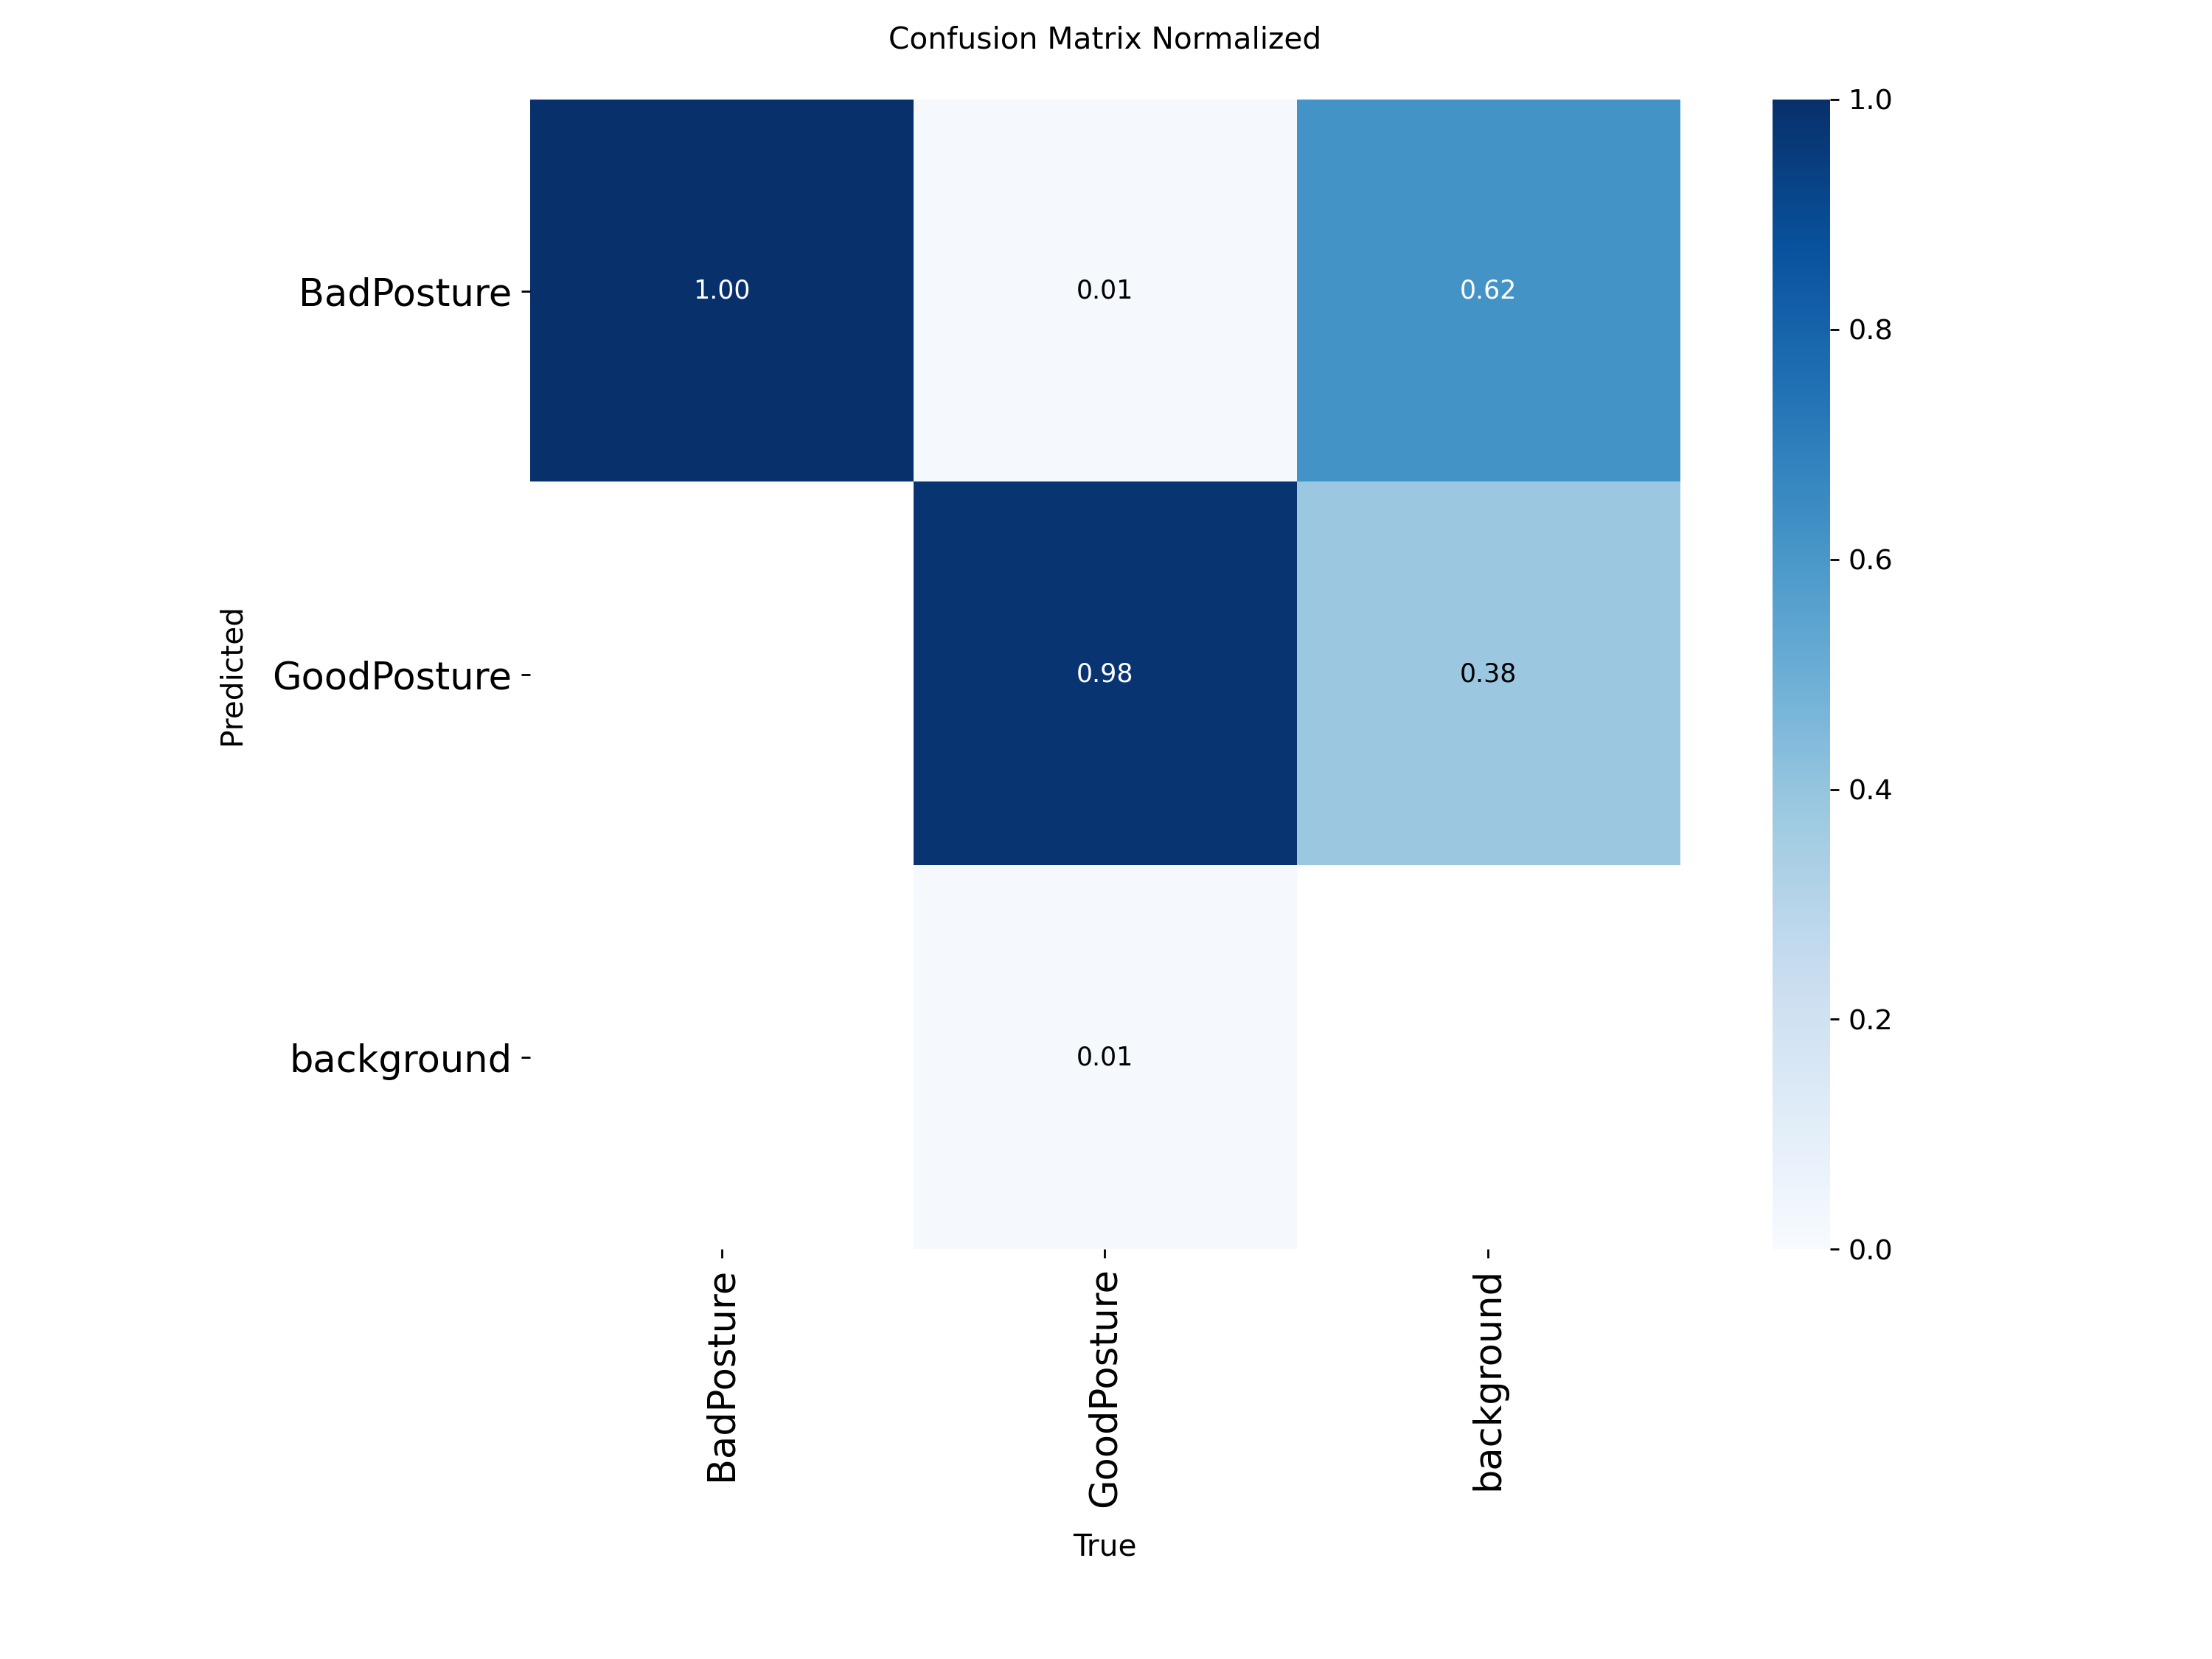

In [ ]:
%matplotlib inline
from PIL import Image

Image.open('/content/drive/MyDrive/Posture Check Computer Vision IAT360/results/train/confusion_matrix_normalized.png')

##Prediction

In [ ]:
model = YOLO("D:/School/SFU/Fall 2026/IAT360/Project 1 Computer Vision/Computer-Vision-Project/Optimal Model/train/weights/best.pt")  # load a custom model

# Predict with the model with any image from internet?
results = model('https://summitphysiotherapy.ca/wp-content/uploads/2017/03/Proper-Sitting-Posture.jpg', save=True, project="D:/School/SFU/Fall 2026/IAT360/Project 1 Computer Vision/Computer-Vision-Project/Optimal Model")


Found https://summitphysiotherapy.ca/wp-content/uploads/2017/03/Proper-Sitting-Posture.jpg locally at Proper-Sitting-Posture.jpg
image 1/1 d:\School\SFU\Fall 2026\IAT360\Project 1 Computer Vision\Computer-Vision-Project\Proper-Sitting-Posture.jpg: 960x736 1 GoodPosture, 17.9ms
Speed: 3.3ms preprocess, 17.9ms inference, 6.8ms postprocess per image at shape (1, 3, 960, 736)
Results saved to D:\School\SFU\Fall 2026\IAT360\Project 1 Computer Vision\Computer-Vision-Project\Optimal Model2\predict


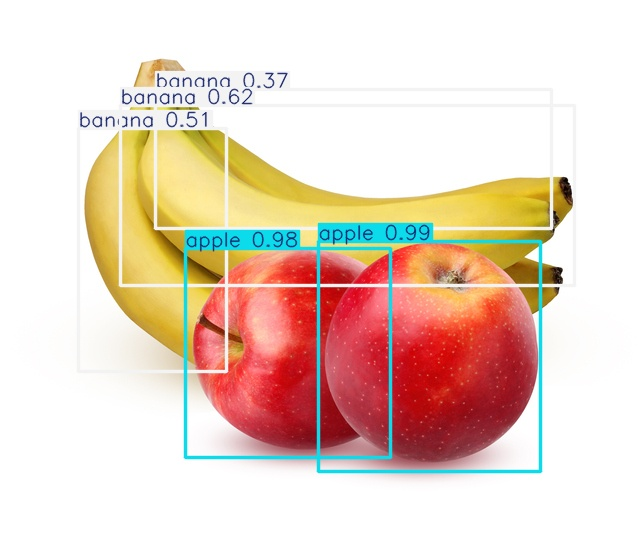

In [ ]:
# SHOW THE IMAGE STORED
%matplotlib inline
from PIL import Image

Image.open('/content/drive/MyDrive/custom_folder/predict-2/freshpoint-produce-101-apples-bananas.jpg')